In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi
import matplotlib

In [3]:
prefix = '/mnt/staging/' # or 
mouse='cm229'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_sensory = str(PREPARES / "index-S1") + "/"
fetch_path_motor = str(PREPARES / "index-M2") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"

h5_root = step_3_root+mouse+'/dlc_h5s/'
video_root = step_3_root+mouse+'/dlc_movies/'
mirror_h5_root = step_3_root+mouse+'/dlc_mirror_h5s/'


path_config = str(PREPARES / "config") + "/"
fetch_path_running = str(PREPARES / "epochs-running") + "/"
fetch_path_rest = str(PREPARES / "epochs-rest") + "/"

figure_config_root = str(PREPARES / "config") + "/"

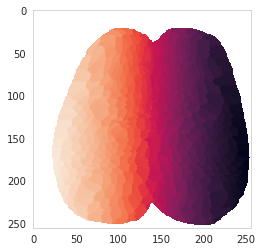

In [4]:
M2_ind = load_pickle(fetch_path_motor+'brightest_frontline_ind-'+mouse)
sensory_ind = load_pickle(fetch_path_sensory+'brightest_ind_'+mouse)
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [5]:
def show_map(data,caxis,if_return_map=False,cmap='rocket'):
    ss_idx = IDX_sorted.shape;
    IDX_reshape = IDX_sorted.reshape((-1,1))
    tmp = np.empty((ss_idx[0]*ss_idx[1],1))
    tmp[:] = np.nan
    std_map = tmp
    ncomps=500
    for i_region in range(ncomps):
        indice = IDX_reshape == i_region+1
        std_map[indice] =  data[i_region]
    # reshape back
    std_map = np.reshape(std_map,(ss_idx[0],ss_idx[1]))
    plt.imshow(std_map,vmin=caxis[0],vmax=caxis[1],cmap=cmap)
    plt.axis('off')
    plt.colorbar(fraction=0.046, pad=0.04)
    if if_return_map ==True:
        return std_map

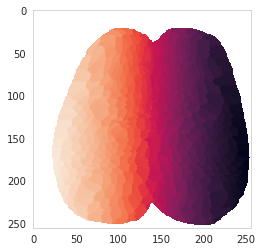

In [6]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
    
plt.imshow(IDX_sorted)


In [7]:
S1_ind = sensory_ind['RFP']

In [8]:
all_gathered = ['M_jrgeco','M_gcamp','M_chbt',
               'M_day_label','M_LFP_vel','M_RFP_vel','M_ind_stop',
                'M_ind','M_rotf','M_is_groom','M_rotf_smooth',
               'M_body_pc','M_face_pc','M_body_pc_smooth',
               'M_mirrorLFP_vel','M_mirrorLFP_vel_norm',
               'M_mirrorRFP_vel','M_mirrorRFP_vel_norm',
               'M_mirrorLHP_vel','M_mirrorLHP_vel_norm',
               'M_mirrorRHP_vel','M_mirrorRHP_vel_norm']

f = scipy.io.loadmat(fetch_path_rest+'final_'+mouse+'_raw.mat'
                       )

for key in all_gathered:
    exec("{} = np.squeeze(f['{}'])".format(key,key))


    

Text(0.5, 1.0, 'M_face_pc')

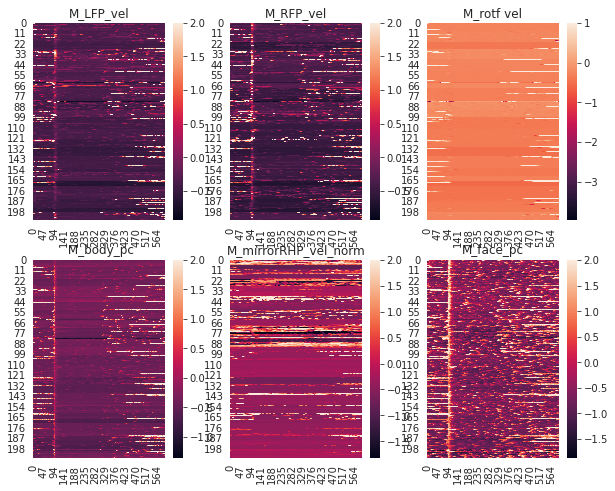

In [9]:
plt.figure(figsize=(10,8))
t_range=range(0,600)
plt.subplot(231)
sns.heatmap(M_LFP_vel[t_range,:].T,vmax=2)
plt.title('M_LFP_vel')
plt.subplot(232)
sns.heatmap(M_RFP_vel[t_range,:].T,vmax=2)
plt.title('M_RFP_vel')
plt.subplot(233)
sns.heatmap(M_rotf[t_range,:].T,vmax=1)
plt.title('M_rotf vel')
plt.subplot(234)
sns.heatmap(M_body_pc[t_range,:].T,vmax=2)
plt.title(' M_body_pc')
plt.subplot(235)
sns.heatmap(M_mirrorRHP_vel_norm[t_range,:].T,vmax=2)
plt.title('M_mirrorRHP_vel_norm')
plt.subplot(236)
sns.heatmap(M_face_pc[t_range,:].T,vmax=2)
plt.title('M_face_pc')

In [10]:
num_bouts = M_rotf.shape[1]
# stopind = np.zeros(num_bouts)
# for i in range(num_bouts):
#     try:
#         stopind[i] = np.argmax(np.where(M_body_pc_smooth[running_onset:,i]<0.2))
#     except:
#         continue
# oo = np.argsort(stopind)
ss_ind = np.argsort(M_ind_stop-M_ind)

In [11]:
M_jrgeco = M_jrgeco[:,:,ss_ind]
M_gcamp = M_gcamp[:,:,ss_ind]
M_chbt = M_chbt[:,:,ss_ind]
M_day_label = M_day_label[ss_ind]
M_ind = M_ind[ss_ind]
M_ind_stop = M_ind_stop[ss_ind]
M_LFP_vel=M_LFP_vel[:,ss_ind]
M_RFP_vel=M_RFP_vel[:,ss_ind]
M_body_pc=M_body_pc[:,ss_ind]
M_face_pc=M_face_pc[:,ss_ind]
M_body_pc_smooth= M_body_pc_smooth[:,ss_ind]
M_rotf=M_rotf[:,ss_ind]
M_rotf_smooth=M_rotf_smooth[:,ss_ind]
M_is_groom=M_is_groom[:,ss_ind]


M_mirrorRFP_vel = M_mirrorRFP_vel[:,ss_ind]
M_mirrorRFP_vel_norm = M_mirrorRFP_vel_norm[:,ss_ind]
M_mirrorLFP_vel = M_mirrorLFP_vel[:,ss_ind]
M_mirrorLFP_vel_norm = M_mirrorLFP_vel_norm[:,ss_ind]
M_mirrorRHP_vel = M_mirrorRHP_vel[:,ss_ind]
M_mirrorRHP_vel_norm = M_mirrorRHP_vel_norm[:,ss_ind]
M_mirrorLHP_vel = M_mirrorLHP_vel[:,ss_ind]
M_mirrorLHP_vel_norm = M_mirrorLHP_vel_norm[:,ss_ind]

<AxesSubplot:>

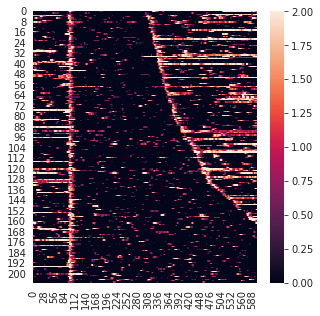

In [12]:
plt.figure(figsize=(5,5))
sns.heatmap(M_face_pc[:,:].transpose(),vmin=-0,vmax=2)

In [13]:
t_stop_resting = (M_ind_stop - M_ind)/4 +100

In [14]:
fake_M_face_pc = M_face_pc.copy()
fake_M_face_pc[:120,:]=np.nan
for i_stop,stop in enumerate(t_stop_resting):
    fake_M_face_pc[int(t_stop_resting[i_stop]):,i_stop]=np.nan

<AxesSubplot:>

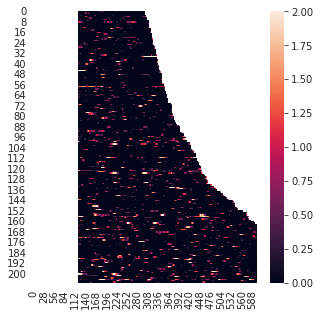

In [15]:
plt.figure(figsize=(5,5))
sns.heatmap(fake_M_face_pc[:,:].transpose(),vmin=-0,vmax=2)

In [16]:
T_PRE_new=130

(193,)


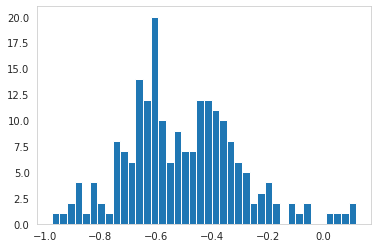

In [17]:
before_running_std = np.nanmean(fake_M_face_pc[:,:],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = -0.2
ss_ind = before_running_std<ss
print(np.where(ss_ind==True)[0].shape)


In [18]:
fake_M_face_pc = fake_M_face_pc[:,ss_ind]

M_jrgeco = M_jrgeco[:,:,ss_ind]
M_gcamp = M_gcamp[:,:,ss_ind]
M_chbt = M_chbt[:,:,ss_ind]
M_day_label = M_day_label[ss_ind]
M_ind = M_ind[ss_ind]
M_ind_stop = M_ind_stop[ss_ind]
M_LFP_vel=M_LFP_vel[:,ss_ind]
M_RFP_vel=M_RFP_vel[:,ss_ind]
M_body_pc=M_body_pc[:,ss_ind]
M_face_pc=M_face_pc[:,ss_ind]
M_body_pc_smooth= M_body_pc_smooth[:,ss_ind]
M_rotf=M_rotf[:,ss_ind]
M_rotf_smooth=M_rotf_smooth[:,ss_ind]
M_is_groom=M_is_groom[:,ss_ind]


M_mirrorRFP_vel = M_mirrorRFP_vel[:,ss_ind]
M_mirrorRFP_vel_norm = M_mirrorRFP_vel_norm[:,ss_ind]
M_mirrorLFP_vel = M_mirrorLFP_vel[:,ss_ind]
M_mirrorLFP_vel_norm = M_mirrorLFP_vel_norm[:,ss_ind]
M_mirrorRHP_vel = M_mirrorRHP_vel[:,ss_ind]
M_mirrorRHP_vel_norm = M_mirrorRHP_vel_norm[:,ss_ind]
M_mirrorLHP_vel = M_mirrorLHP_vel[:,ss_ind]
M_mirrorLHP_vel_norm = M_mirrorLHP_vel_norm[:,ss_ind]

(102,)


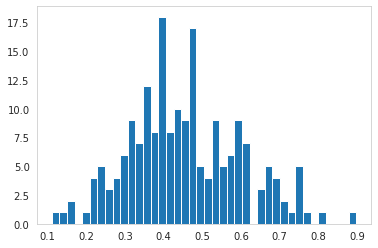

In [19]:
before_running_std = np.nanstd(fake_M_face_pc[:,:],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = 0.45
ss_ind = before_running_std<ss
print(np.where(ss_ind==True)[0].shape)


In [20]:
fake_M_face_pc = fake_M_face_pc[:,ss_ind]

M_jrgeco = M_jrgeco[:,:,ss_ind]
M_gcamp = M_gcamp[:,:,ss_ind]
M_chbt = M_chbt[:,:,ss_ind]
M_day_label = M_day_label[ss_ind]
M_ind = M_ind[ss_ind]
M_ind_stop = M_ind_stop[ss_ind]
M_LFP_vel=M_LFP_vel[:,ss_ind]
M_RFP_vel=M_RFP_vel[:,ss_ind]
M_body_pc=M_body_pc[:,ss_ind]
M_face_pc=M_face_pc[:,ss_ind]
M_body_pc_smooth= M_body_pc_smooth[:,ss_ind]
M_rotf=M_rotf[:,ss_ind]
M_rotf_smooth=M_rotf_smooth[:,ss_ind]
M_is_groom=M_is_groom[:,ss_ind]


M_mirrorRFP_vel = M_mirrorRFP_vel[:,ss_ind]
M_mirrorRFP_vel_norm = M_mirrorRFP_vel_norm[:,ss_ind]
M_mirrorLFP_vel = M_mirrorLFP_vel[:,ss_ind]
M_mirrorLFP_vel_norm = M_mirrorLFP_vel_norm[:,ss_ind]
M_mirrorRHP_vel = M_mirrorRHP_vel[:,ss_ind]
M_mirrorRHP_vel_norm = M_mirrorRHP_vel_norm[:,ss_ind]
M_mirrorLHP_vel = M_mirrorLHP_vel[:,ss_ind]
M_mirrorLHP_vel_norm = M_mirrorLHP_vel_norm[:,ss_ind]

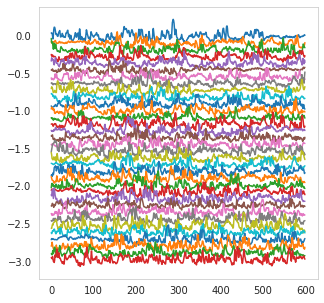

In [21]:
plt.figure(figsize=(5,5))
for i in range(0,M_jrgeco.shape[-1],3):
    plt.plot(M_jrgeco[sensory_ind['LM'],:,i]-0.03*i)

In [22]:
M_jrgeco.shape

(500, 600, 102)

(0.0, 600.0)

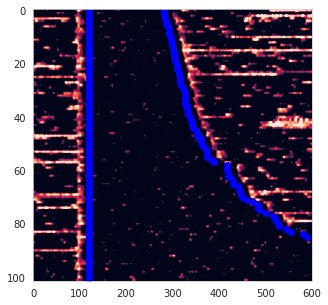

In [23]:
T_PRE_REST = 120
t_stop_resting = (M_ind_stop - M_ind)/4 +100-20
t_stop_resting=t_stop_resting.astype('int')

plt.figure(figsize=(5,5))
plt.imshow(M_face_pc[:,:].transpose(),vmin=-0,vmax=2,aspect='auto')
for i_stop,stop_ind in enumerate(t_stop_resting):
    plt.scatter(stop_ind,i_stop,color='blue')
    plt.scatter(T_PRE_REST,i_stop,color='blue')
plt.xlim([0,600])

In [24]:
with h5py.File(figure_config_root+'mask_midline_'+mouse+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T

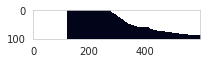

In [25]:
mask_baseline = np.ones_like(M_face_pc)
mask_baseline[:120,:]=np.nan
for i_stop,stop in enumerate(t_stop_resting):
    mask_baseline[int(t_stop_resting[i_stop]):,i_stop]=np.nan
plt.figure(figsize=(3,2))
plt.imshow(mask_baseline.T)
# plt.colorbar()

# spectrogram

In [29]:
mask_baseline_multiple = np.repeat(
    mask_baseline[np.newaxis,:,:],axis=0,repeats=500)

In [30]:
norm_baseline_value = np.nanmean(np.multiply(mask_baseline_multiple,M_jrgeco),1)[:,np.newaxis,:]
norm_M_jrgeco  = M_jrgeco  - norm_baseline_value

norm_baseline_value = np.nanmean(np.multiply(mask_baseline_multiple,M_gcamp),1)[:,np.newaxis,:]
norm_M_gcamp  = M_gcamp  - norm_baseline_value

norm_baseline_value = np.nanmean(np.multiply(mask_baseline,M_RFP_vel),0)[np.newaxis,:]
norm_M_RFP  = M_RFP_vel  - norm_baseline_value

In [55]:
choice_body_part_dict = {0:'RFP_S1',1:'RFP_M1',2:'RFP_M2'}
choice_dict = {0:sensory_ind['RFP'],1:322,2:M2_ind['RFP']}
jrgeco2plot ={};gcamp2plot ={};
for i_bdp in range(3):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    jrgeco2plot[bdp]=norm_M_jrgeco[ind,:,:]
    gcamp2plot[bdp]=norm_M_gcamp[ind,:,:]




In [56]:
def make_spectrogram(mean_of_regions,fs):
    ss = mean_of_regions.shape
    t_ss = ss[0] # time 650
    num_bouts = ss[1] # bouts
    
    # concat 
    # CAUTION: TRANSPOSE HERE IS IMPORTANT
    x = mean_of_regions.transpose().reshape((1,-1))
    # NOW TIME COURSES ARE CONCATED
    long_ss = x.shape[1]
    
    f, t, Sxx = signal.spectrogram(x, fs ,noverlap=18,nperseg=30,nfft=300)
    Sxx = np.squeeze(Sxx)
    num_freq_bins = Sxx.shape[0]
    
    Slinn = np.zeros((num_freq_bins,long_ss))
    for i in range(num_freq_bins):
        Slinn[i,:] = np.interp(np.divide(range(long_ss),fs),t,np.abs(Sxx[i,:]));
    Slinn = Slinn.reshape((num_freq_bins,num_bouts,t_ss))
    return Slinn,f

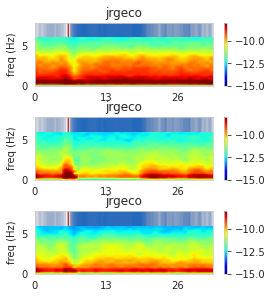

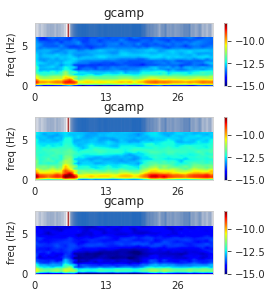

In [57]:
x = range(M_body_pc.shape[0])
my_xticks = np.divide(range(M_body_pc.shape[0]),15)
y = range(M_body_pc.shape[1])
my_yticks = range(M_body_pc.shape[1])

dict_slinn,dict_f = {'jrgeco':{},'gcamp':{}},{'jrgeco':{},'gcamp':{}}

for fluorophore in ['jrgeco','gcamp']:
    plt.figure(figsize=(4,15))
    for i_bdp in range(3):
        bdp = choice_body_part_dict[i_bdp]
        ind = choice_dict[i_bdp]
        # params = {"text.color" : colors[i]}
        # plt.rcParams.update(params)
        plt.subplot(9,1,i_bdp+1)

        exec("Slinn,f = make_spectrogram({}2plot[bdp],fs=15)".format(fluorophore))
        dict_slinn[fluorophore][bdp] = Slinn
        dict_f[fluorophore][bdp]=f

    #         plt.pcolormesh(x, f, np.log(np.mean(Slinn,axis=1)),cmap='vlag')
        plt.pcolormesh(x, f, np.log(np.mean(Slinn,axis=1)),cmap='jet',vmin=-15,vmax=-8)
        plt.colorbar()
        plt.xticks(np.array(x[::200],dtype='int'), 
               np.array(my_xticks[::200],dtype='int'));

    #         plt.xticks([]);plt.yticks([])
        plt.ylim([0,7.9])
        plt.xlim([0,500])

        beh2plot = M_body_pc
        avg = np.mean(beh2plot,axis=1)
        avg = normalize(avg)
    #         plt.scatter(range(len(avg)),np.ones((len(avg)))*0.11+11.2,marker="|",s=950,c=avg,cmap='magma')
        plt.scatter(range(len(avg)),np.ones((len(avg)))*0.11+8,marker="|",s=1050,c=avg,cmap='vlag')
        plt.title(fluorophore)
        plt.ylabel('freq (Hz)')
        if i_bdp==4:
            plt.xlabel('time (s)')
    plt.subplots_adjust(hspace=0.5)



In [67]:
norm_M_RFP.shape

(600, 102)

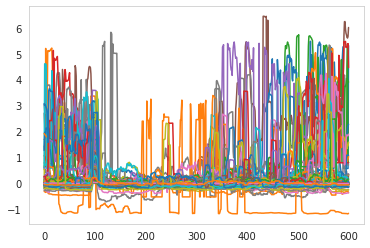

In [69]:
for i in range(102):
    plt.plot(norm_M_RFP[:,i])

In [ ]:
plt.plot(

Text(0, 0.5, 'freq (Hz)')

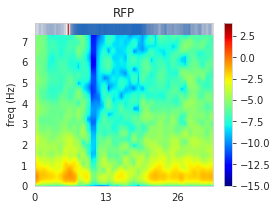

In [64]:
x = range(M_body_pc.shape[0])
my_xticks = np.divide(range(M_body_pc.shape[0]),15)
y = range(M_body_pc.shape[1])
my_yticks = range(M_body_pc.shape[1])

dict_slinn_behavior,dict_f_behavior = [],[]

plt.figure(figsize=(4,3))

Slinn,f = make_spectrogram(norm_M_RFP,fs=15)
dict_slinn_behavior = Slinn
dict_f_behavior=f

#         plt.pcolormesh(x, f, np.log(np.mean(Slinn,axis=1)),cmap='vlag')
plt.pcolormesh(x, f, np.log(np.mean(Slinn,axis=1)),cmap='jet',vmin=-15,vmax=4)
plt.colorbar()
plt.xticks(np.array(x[::200],dtype='int'), 
       np.array(my_xticks[::200],dtype='int'));

#         plt.xticks([]);plt.yticks([])
plt.ylim([0,7.9])
plt.xlim([0,500])

beh2plot = M_body_pc
avg = np.mean(beh2plot,axis=1)
avg = normalize(avg)
#         plt.scatter(range(len(avg)),np.ones((len(avg)))*0.11+11.2,marker="|",s=950,c=avg,cmap='magma')
plt.scatter(range(len(avg)),np.ones((len(avg)))*0.11+8,marker="|",s=1050,c=avg,cmap='vlag')
plt.title('RFP')
plt.ylabel('freq (Hz)')





In [61]:
ss = norm_M_jrgeco.shape
norm_M_jrgeco_std = np.empty((ss[0],ss[1],0))
norm_M_gcamp_std = np.empty((ss[0],ss[1],0))
for i_bout in range(ss[2]):
    # jrgeco
    temp = pd.DataFrame(norm_M_jrgeco[:,:,i_bout]).rolling(15,axis=1).std().values
    norm_M_jrgeco_std=np.append(norm_M_jrgeco_std,temp[:,:,np.newaxis],axis=2)
    # gcamp
    temp = pd.DataFrame(norm_M_gcamp[:,:,i_bout]).rolling(15,axis=1).std().values
    norm_M_gcamp_std=np.append(norm_M_gcamp_std,temp[:,:,np.newaxis],axis=2)

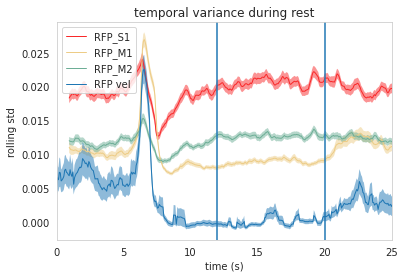

In [71]:
palatte_dict={}
palatte_dict['LM_M1']='#edcc86'
palatte_dict['LM_M2']='#6dae96'
palatte_dict['LM_S1'] = '#f9292a' #palatte_dict['RFP']
t_ax_2show = np.divide(range(norm_M_jrgeco_zscore_std.shape[1]),15)
for ii,iroi in enumerate(choice_body_part_dict.keys()):
    ind_roi='LM'
    bdp_here = choice_body_part_dict[iroi]
    cortex = bdp_here.split('_')[1]
    ind = choice_dict[iroi]
    avg = np.mean(norm_M_jrgeco_std[ind,:,:],-1)
    plt.plot(t_ax_2show,avg,color=palatte_dict[ind_roi+'_'+cortex],label = bdp_here,linewidth=1)
    sem = stats.sem(norm_M_jrgeco_std[ind,:,:],-1)
    plt.fill_between(t_ax_2show,avg - sem,avg + sem,color=palatte_dict[ind_roi+'_'+cortex],alpha=0.5,linewidth=0)


avg = np.mean(norm_M_RFP[:,:],-1)/40
plt.plot(t_ax_2show,avg,color='tab:blue',label = 'RFP vel',linewidth=1)
sem = stats.sem(norm_M_RFP[:,:],-1)/40
plt.fill_between(t_ax_2show,avg - sem,avg + sem,color='tab:blue',alpha=0.5,linewidth=0)


plt.xlim([0,25])
plt.ylabel('rolling std');plt.xlabel('time (s)')
plt.title('temporal variance during rest')
plt.axvline(t_ax_2show[180]);plt.axvline(t_ax_2show[300])
plt.legend()


**trim data. keep duration of pure rest**

In [72]:
trimmed_range = range(180,300)
jrgeco2plot_trimmed = jrgeco2plot.copy()
for key in jrgeco2plot_trimmed.keys():
    jrgeco2plot_trimmed[key] = jrgeco2plot_trimmed[key][trimmed_range,:]
trimmed_dict_slinn = dict_slinn.copy()
for fluorophore in ['jrgeco','gcamp']:
    for bdp in trimmed_dict_slinn[fluorophore].keys():
        trimmed_dict_slinn[fluorophore][bdp] = trimmed_dict_slinn[fluorophore][bdp][:,:,trimmed_range]
        


In [73]:
trimmed_dict_slinn_behavior = dict_slinn_behavior[:,:,trimmed_range]

In [ ]:
dict_everything_save = {
'choice_body_part_dict':choice_body_part_dict,
'choice_dict':choice_dict,
'dict_slinn':dict_slinn,
'dict_f':dict_f,
'IDX_sorted':IDX_sorted,
'norm_M_jrgeco':norm_M_jrgeco[:,trimmed_range,:],
'norm_M_gcamp':norm_M_gcamp[:,trimmed_range,:],
'norm_M_RFP':norm_M_RFP[trimmed_range,:],
'norm_M_jrgeco_std':norm_M_jrgeco_std[:,trimmed_range,:],
'norm_M_gcamp_std':norm_M_gcamp_std[:,trimmed_range,:],
'node_coords':node_coords,
'trimmed_range':trimmed_range,
'trimmed_dict_slinn':trimmed_dict_slinn,
'jrgeco2plot_trimmed':jrgeco2plot_trimmed,
'trimmed_dict_slinn_behavior':trimmed_dict_slinn_behavior,
}
save_root = str(FIGURES / "figureS4") + "/"
save_pickle(dict_everything_save,save_root+'csn-thy1-compare-trimmed-REST-'+mouse)